# 02 – Text analysis of chatbot answers (and news, when available)

TF-IDF, n-grams, collocations and VADER sentiment (plan Days 4–5).

**Design decisions (put these in the method section)**
- **Unit of analysis = prompt.** Each prompt has 2 replicates per chatbot. Replicates are the same question asked twice, not independent texts, so sentiment is averaged per prompt × chatbot before any group comparison (n = 54 per chatbot, not 108). Bootstrap intervals resample prompts.
- **Prompt words are removed.** Answers repeat words from the question ("government", "AI", "rules"). Without removing them, group differences mostly reflect the question text, not the chatbot. The list is built from the 54 prompts.
- **Same preprocessing for chatbot and news text:** spaCy lemmas, lower-case, alphabetic tokens, stop words removed.
- **The news part switches on by itself** when `data/news_clean.csv` exists. **Length rule (agreed by the team): every text is cut to its first 300 words** (`MAX_WORDS`), chatbot answers and news alike, in the chatbot-vs-news comparison. Note that cutting cannot lengthen short texts: Llama answers average 223 words and some news articles are under 300, so length still differs below the cap and has to be reported and controlled for in the H1 analysis.

In [1]:
import json, re
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import spacy
from nltk.collocations import BigramCollocationFinder, BigramAssocMeasures
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

SEED = 42
rng = np.random.default_rng(SEED)
CFG = json.load(open("config.json"))       # all data paths live in config.json
OUT = Path(CFG["analysis_dir"]); OUT.mkdir(parents=True, exist_ok=True)

ANSWERS = Path(CFG["answers_jsonl"])
PROMPTS = Path(CFG["prompts_csv"])
NEWS_CSV = Path(CFG["news_corpus_csv"])     # git-ignored (article text belongs to the publishers)
MAX_WORDS = 300                             # agreed length rule: first 300 words of every text (chatbot and news)
CHATBOTS = ["llama3.1:8b", "qwen3.5:9b"]    # gemini rows are ignored
WORDINGS = ["neutral", "leaning_for", "leaning_against"]
COLORS = {"llama3.1:8b": "#2a78d6", "qwen3.5:9b": "#eb6834"}   # validated categorical slots 1 and 2

nlp = spacy.load("en_core_web_sm", disable=["ner", "parser"])

## 1. Load answers

In [2]:
ans = pd.read_json(ANSWERS, lines=True)
ans = ans[ans["chatbot"].isin(CHATBOTS)].reset_index(drop=True)
prompts = pd.read_csv(PROMPTS)
print(len(ans), "answers;", ans["prompt_id"].nunique(), "prompts")
ans.groupby(["chatbot", "wording"])["n_words"].describe()[["count", "mean", "min", "max"]].round(0)

216 answers; 54 prompts


count   mean    min    max
chatbot     wording                                    
llama3.1:8b leaning_against   36.0  221.0  176.0  256.0
            leaning_for       36.0  221.0  188.0  248.0
            neutral           36.0  228.0  189.0  263.0
qwen3.5:9b  leaning_against   36.0  302.0  268.0  359.0
            leaning_for       36.0  282.0  257.0  343.0
            neutral           36.0  300.0  260.0  336.0

## 2. Preprocessing
Lemmatise with spaCy, keep alphabetic non-stop-word tokens, and drop every lemma that appears in the 54 prompts.
Both the full token list and a version without prompt words are kept: sentiment uses the raw text, the word statistics use the cleaned tokens.

In [3]:
def lemmas(texts):
    out = []
    for doc in nlp.pipe(texts, batch_size=64):
        out.append([t.lemma_.lower() for t in doc if t.is_alpha and not t.is_stop and len(t) > 2])
    return out

prompt_vocab = set(w for toks in lemmas(prompts["prompt"]) for w in toks)
print(len(prompt_vocab), "prompt lemmas removed, e.g.", sorted(prompt_vocab)[:15])

ans["tokens_all"] = lemmas(ans["answer"])
ans["tokens"] = ans["tokens_all"].map(lambda ts: [t for t in ts if t not in prompt_vocab])
ans["text_clean"] = ans["tokens"].str.join(" ")
print("mean content tokens per answer:", round(ans["tokens"].map(len).mean(), 1),
      "(", round(ans["tokens_all"].map(len).mean() - ans["tokens"].map(len).mean(), 1), "removed as prompt words )")

76 prompt lemmas removed, e.g. ['adopt', 'advanced', 'agency', 'agree', 'approval', 'area', 'bad', 'campaign', 'cause', 'company', 'content', 'country', 'create', 'datum', 'decision']


mean content tokens per answer: 115.9 ( 33.3 removed as prompt words )


## 3. TF-IDF: most distinctive words per group
Each group (chatbot × wording) is treated as one document, so a word scores high when it is frequent in that group and rare in the others.

In [4]:
groups = ans.groupby(["chatbot", "wording"])["text_clean"].apply(" ".join).reset_index()
groups["group"] = groups["chatbot"] + " | " + groups["wording"]

tfidf = TfidfVectorizer(sublinear_tf=True, min_df=1)
M = tfidf.fit_transform(groups["text_clean"])
terms = np.array(tfidf.get_feature_names_out())

rows = []
for i, g in enumerate(groups["group"]):
    row = M[i].toarray().ravel()
    for j in row.argsort()[::-1][:15]:
        rows.append({"group": g, "term": terms[j], "tfidf": round(row[j], 3)})
tfidf_top = pd.DataFrame(rows)
tfidf_top.to_csv(OUT / "tfidf_top_by_group.csv", index=False)
tfidf_top.groupby("group")["term"].apply(lambda s: ", ".join(s.head(10)))

group
llama3.1:8b | leaning_against    actually, hinder, situation, lead, choose, rel...
llama3.1:8b | leaning_for        help, malfunction, ensure, way, ethnic, lead, ...
llama3.1:8b | neutral            aspect, help, hand, ensure, potential, innovat...
qwen3.5:9b | leaning_against     legal, prohibition, ban, rigid, yield, paradox...
qwen3.5:9b | leaning_for         legal, channel, ethical, crisis, speed, baseli...
qwen3.5:9b | neutral             proponent, baseline, calibrate, harmful, halt,...
Name: term, dtype: object

## 4. N-grams
Bigrams and trigrams on the cleaned lemmas. `min_df=3` keeps only phrases that occur in at least 3 different answers, so one answer repeating itself cannot make a phrase look common.

In [5]:
def top_ngrams(texts, n=(2, 3), k=15, min_df=3):
    cv = CountVectorizer(ngram_range=n, min_df=min_df)
    X = cv.fit_transform(texts)
    counts = np.asarray(X.sum(axis=0)).ravel()
    docs = np.asarray((X > 0).sum(axis=0)).ravel()
    order = counts.argsort()[::-1][:k]
    names = cv.get_feature_names_out()
    return pd.DataFrame({"ngram": names[order], "count": counts[order], "answers": docs[order]})

ng = []
for (bot, wording), g in ans.groupby(["chatbot", "wording"]):
    t = top_ngrams(g["text_clean"]); t.insert(0, "wording", wording); t.insert(0, "chatbot", bot); ng.append(t)
for bot, g in ans.groupby("chatbot"):
    t = top_ngrams(g["text_clean"]); t.insert(0, "wording", "all"); t.insert(0, "chatbot", bot); ng.append(t)
ngrams = pd.concat(ng, ignore_index=True)
ngrams.to_csv(OUT / "ngrams_top.csv", index=False)
ngrams[ngrams["wording"] == "all"]

,chatbot,wording,ngram,count,answers
90,llama3.1:8b,all,transparency accountability,34,29
91,llama3.1:8b,all,stifle innovation,33,33
92,llama3.1:8b,all,ensure develop,25,20
93,llama3.1:8b,all,help ensure,25,25
94,llama3.1:8b,all,unintended consequence,24,23
95,llama3.1:8b,all,establish clear,22,18
96,llama3.1:8b,all,build trust,22,22
97,llama3.1:8b,all,potential risk,22,19
98,llama3.1:8b,all,help build trust,20,20
99,llama3.1:8b,all,clear guideline,20,16


## 5. Collocations
Word pairs that occur together more often than chance, ranked by PMI. PMI favours rare pairs, so pairs seen fewer than 5 times are dropped and the window is 3 words. Log-likelihood is shown alongside because it favours frequent pairs; a pair that ranks high on both is the safest to report.

In [6]:
def collocations(token_lists, window=3, min_freq=5, k=15):
    finder = BigramCollocationFinder.from_documents(token_lists)
    finder.window_size = window
    finder.apply_freq_filter(min_freq)
    m = BigramAssocMeasures()
    pmi = dict(finder.score_ngrams(m.pmi)); llr = dict(finder.score_ngrams(m.likelihood_ratio))
    df = pd.DataFrame([{"pair": " ".join(p), "freq": finder.ngram_fd[p], "pmi": round(pmi[p], 2), "llr": round(llr[p], 1)}
                       for p in pmi])
    return df.sort_values("pmi", ascending=False).head(k) if len(df) else df

col = []
for bot, g in ans.groupby("chatbot"):
    t = collocations(g["tokens"].tolist()); t.insert(0, "chatbot", bot); col.append(t)
colloc = pd.concat(col, ignore_index=True)
colloc.to_csv(OUT / "collocations_by_chatbot.csv", index=False)
colloc

,chatbot,pair,freq,pmi,llr
0,llama3.1:8b,vast amount,7,9.02,40.8
1,llama3.1:8b,chilling effect,6,8.99,34.5
2,llama3.1:8b,push boundary,6,8.99,34.5
3,llama3.1:8b,demonstrate commitment,7,8.85,39.7
4,llama3.1:8b,assign blame,5,8.76,27.5
5,llama3.1:8b,careful consideration,8,8.70,44.6
6,llama3.1:8b,artificial intelligence,14,8.22,74.3
7,llama3.1:8b,law enforcement,10,8.18,51.6
8,llama3.1:8b,critical infrastructure,7,8.13,35.3
9,llama3.1:8b,data collection,5,8.12,25.1


## 6. VADER sentiment
VADER runs on the raw text (it uses punctuation and negation, so no lemmatising). **The score is computed per sentence and averaged**: VADER's whole-text compound score is squashed towards ±1 as text gets longer (here most answers scored 0.7–0.96), so it would measure length rather than tone. The whole-text score is kept in a column for comparison. Replicates are averaged per prompt × chatbot first, then summarised with a bootstrap 95% interval over prompts.

In [7]:
sia = SentimentIntensityAnalyzer()
def sentence_compound(text):
    sents = [s for s in re.split(r"(?<=[.!?])\s+", text.strip()) if s]
    return float(np.mean([sia.polarity_scores(s)["compound"] for s in sents]))

ans["vader_whole"] = ans["answer"].map(lambda t: sia.polarity_scores(t)["compound"])
ans["vader"] = ans["answer"].map(sentence_compound)
print("whole-text compound: median", ans["vader_whole"].median().round(2), "| share above 0.9:", (ans["vader_whole"] > 0.9).mean().round(2),
      "| sentence-mean: median", ans["vader"].median().round(2))

per_prompt = (ans.groupby(["chatbot", "wording", "question_id", "topic_frame"], as_index=False)["vader"].mean())

def boot_ci(x, n=5000):
    x = np.asarray(x); means = rng.choice(x, (n, len(x))).mean(axis=1)
    return np.percentile(means, [2.5, 97.5])

rows = []
for (bot, w), g in per_prompt.groupby(["chatbot", "wording"]):
    lo, hi = boot_ci(g["vader"])
    rows.append({"chatbot": bot, "wording": w, "n_prompts": len(g), "mean": g["vader"].mean(), "ci_low": lo, "ci_high": hi})
sent = pd.DataFrame(rows)
sent.to_csv(OUT / "vader_by_chatbot_wording.csv", index=False)
sent.round(3)

whole-text compound: median 0.97 | share above 0.9: 0.76 | sentence-mean: median 0.24


,chatbot,wording,n_prompts,mean,ci_low,ci_high
0,llama3.1:8b,leaning_against,18,0.150,0.096,0.206
1,llama3.1:8b,leaning_for,18,0.292,0.221,0.364
2,llama3.1:8b,neutral,18,0.304,0.244,0.366
3,qwen3.5:9b,leaning_against,18,0.163,0.114,0.212
4,qwen3.5:9b,leaning_for,18,0.291,0.232,0.350
5,qwen3.5:9b,neutral,18,0.236,0.185,0.289


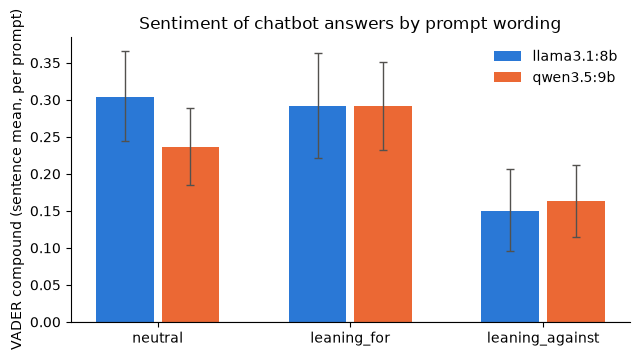

In [8]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
width = 0.34
for k, bot in enumerate(CHATBOTS):
    d = sent[sent["chatbot"] == bot].set_index("wording").loc[WORDINGS]
    x = np.arange(len(WORDINGS)) + (k - 0.5) * width
    ax.bar(x, d["mean"], width=width - 0.04, color=COLORS[bot], label=bot)
    ax.errorbar(x, d["mean"], yerr=[d["mean"] - d["ci_low"], d["ci_high"] - d["mean"]], fmt="none", ecolor="#52514e", capsize=3, lw=1)
ax.axhline(0, color="#52514e", lw=0.8)
ax.set_xticks(range(len(WORDINGS))); ax.set_xticklabels(WORDINGS)
ax.set_ylabel("VADER compound (sentence mean, per prompt)"); ax.set_title("Sentiment of chatbot answers by prompt wording")
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); fig.savefig(OUT / "vader_by_wording.png", dpi=200); plt.show()

Note on reading VADER: it was built for short social-media text. On argumentative prose it mostly measures the share of positive words ("benefits", "protect") against negative ones ("risk", "harm"), not the writer's stance. Report it as a tone measure, not as stance.

## 7. Chatbot vs news (runs only when `data/news_clean.csv` exists)
Distinctive words via **weighted log-odds with an informative Dirichlet prior** (Monroe et al. 2008): unlike raw frequencies it does not reward rare words, and the z-score says how reliable the difference is. A positive z means more typical of chatbot answers, negative more typical of news.

In [9]:
if not NEWS_CSV.exists():
    print("No", NEWS_CSV, "yet - skipping the chatbot-vs-news comparison. Rerun this notebook when the corpus is built.")
else:
    news = pd.read_csv(NEWS_CSV, keep_default_na=False)
    cut = lambda t: " ".join(t.split()[:MAX_WORDS])
    news["tokens"] = [[t for t in ts if t not in prompt_vocab] for ts in lemmas(news["text"].map(cut))]
    ans["tokens_cut"] = [[t for t in ts if t not in prompt_vocab] for ts in lemmas(ans["answer"].map(cut))]
    print(len(news), "news articles, all texts cut to", MAX_WORDS, "words;", news["region"].value_counts().to_dict())
    print("words after cut - news: median", int(news["text"].map(lambda t: min(len(t.split()), MAX_WORDS)).median()),
          "| chatbot:", ans.assign(w=ans["answer"].map(lambda t: min(len(t.split()), MAX_WORDS))).groupby("chatbot")["w"].median().to_dict())

    def log_odds(c1, c2, alpha_total=500):
        vocab = sorted(set(c1) | set(c2)); prior = Counter(c1) + Counter(c2)
        a0 = alpha_total; tot = sum(prior.values())
        n1, n2 = sum(c1.values()), sum(c2.values()); rows = []
        for w in vocab:
            a = a0 * prior[w] / tot
            y1, y2 = c1.get(w, 0), c2.get(w, 0)
            d = np.log((y1 + a) / (n1 + a0 - y1 - a)) - np.log((y2 + a) / (n2 + a0 - y2 - a))
            var = 1 / (y1 + a) + 1 / (y2 + a)
            rows.append((w, y1, y2, d / np.sqrt(var)))
        return pd.DataFrame(rows, columns=["term", "chatbot_count", "news_count", "z"])

    cb = Counter(t for ts in ans["tokens_cut"] for t in ts); nw = Counter(t for ts in news["tokens"] for t in ts)
    lo = log_odds(cb, nw); lo = lo[(lo["chatbot_count"] + lo["news_count"]) >= 10].sort_values("z")
    lo.to_csv(OUT / "chatbot_vs_news_log_odds.csv", index=False)
    print("Most news-like:", ", ".join(lo.head(15)["term"]))
    print("Most chatbot-like:", ", ".join(lo.tail(15)["term"][::-1]))

420 news articles, all texts cut to 300 words; {'US': 133, 'Other': 104, 'UK': 101, 'EU': 82}
words after cut - news: median 300 | chatbot: {'llama3.1:8b': 224.0, 'qwen3.5:9b': 288.0}
Most news-like: say, model, agent, year, chatbot, platform, anthropic, image, google, include, microsoft, business, software, claude, generative
Most chatbot-like: ensure, innovation, regulation, approach, potential, lead, risk, accountability, ultimately, standard, transparency, establish, regulatory, benefit, individual


## Limits to state in the report
- Chatbot answers were asked for "about 250 words of plain prose, without headings"; news is not. Differences in n-grams may partly be style, which is why the plan has a separate style check.
- Qwen answers are about 70 words longer than Llama's (mean 295 vs 223), so raw counts are not comparable across chatbots. Use TF-IDF, rates or the log-odds z-scores, not raw counts.
- Only two chatbots, both run locally with temperature 0.7; results describe those models and settings.